# 15 · Stereo depth and 3D

**Level:** Advanced / guided expert practice  
**Prerequisites:** Camera intrinsics and extrinsics; Grayscale images; Array masks

## What you will build and learn

- Estimate disparity on a synthetic rectified stereo pair
- Convert disparity to metric depth with explicit units
- Handle invalid estimates and triangulate 3D points

## How to use this lesson

Run cells in order with **Shift+Enter**. Predict the result before running each example, then change one parameter and explain what changed. Every default example works offline after setup. Each notebook creates its own data, so previous notebooks do not need to have been run.

Try the exercises before reading the worked solutions. Use **Kernel → Restart Kernel and Run All Cells** to check that your work is reproducible. Keep your own changes in a duplicate notebook if you want to retain the reference version.


## Setup

The cell below imports the libraries and the small display/file helpers. Algorithms are written in the lesson cells. Color arrays passed to `show_images` are assumed to be BGR (OpenCV's usual order); the helper converts them to RGB for Matplotlib. Grayscale arrays are displayed directly. `rng` is a repeatable random generator, so running the notebook again reproduces its sample data.


In [1]:
from pathlib import Path
import sys

# Locate the project whether Jupyter starts in the project or notebooks folder.
start = Path.cwd().resolve()
ROOT = next((p for p in (start, *start.parents) if (p / "course_utils.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook from inside the OpenCV Practical project.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import cv2
import numpy as np
import matplotlib.pyplot as plt
from course_utils import show_images, make_scene, load_image, save_image

rng = np.random.default_rng(42)
cv2.setRNGSeed(42)
plt.rcParams.update({"figure.dpi": 100, "font.size": 10})
print(f"OpenCV {cv2.__version__} | NumPy {np.__version__}")


OpenCV 4.14.0 | NumPy 2.5.3


## Step 1 — Construct a rectified stereo pair
For rectified cameras with equal intrinsics, corresponding points lie on the same image row. Left disparity is `d = x_left - x_right`. With focal length `f` in pixels and baseline `B` in metres, depth is `Z = f*B/d` in metres.

We synthesize a textured fronto-parallel plane with disparity **12 pixels**, focal length **240 pixels**, and baseline **0.10 metres**. Its true depth is **2 metres**. The data is already rectified; arbitrary side-by-side photographs cannot use this formula directly.


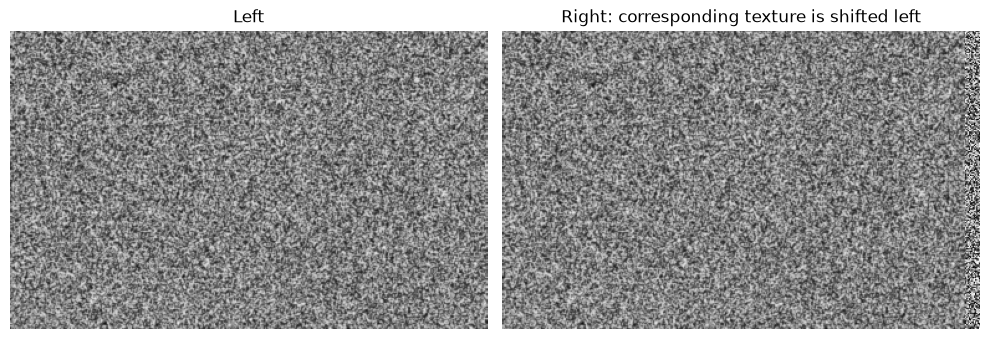

Known plane depth: 2.0 metres


In [2]:
stereo_rng = np.random.default_rng(150)
h, w = 240, 384
left = stereo_rng.integers(0, 256, (h, w), dtype=np.uint8)
left = cv2.GaussianBlur(left, (3, 3), 0.6)
disparity_true = 12
focal_px, baseline_m = 240.0, 0.10
depth_true_m = focal_px * baseline_m / disparity_true
right = np.zeros_like(left)
right[:, :-disparity_true] = left[:, disparity_true:]
right[:, -disparity_true:] = stereo_rng.integers(0, 256, (h, disparity_true), dtype=np.uint8)
show_images([left, right], ['Left', 'Right: corresponding texture is shifted left'])
print('Known plane depth:', depth_true_m, 'metres')


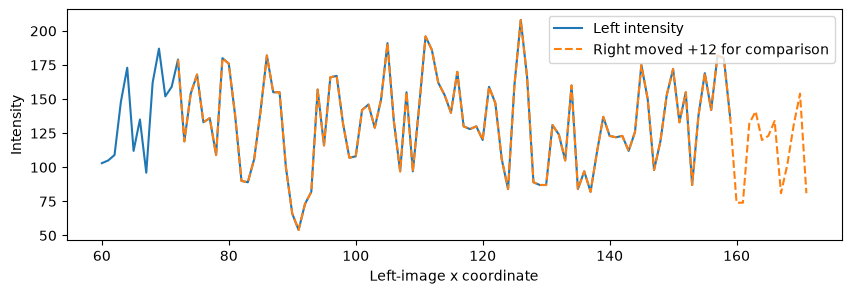

In [3]:
row = 100
plt.figure(figsize=(10, 3))
plt.plot(np.arange(60, 160), left[row, 60:160], label='Left intensity')
plt.plot(np.arange(60, 160)+disparity_true, right[row, 60:160], '--', label='Right moved +12 for comparison')
plt.xlabel('Left-image x coordinate'); plt.ylabel('Intensity'); plt.legend(); plt.show()
assert np.array_equal(left[:, disparity_true:], right[:, :-disparity_true])


## Step 2 — Match scanlines with StereoSGBM
Semi-global block matching balances local appearance with smoothness along several directions. `numDisparities` must be divisible by 16; `blockSize` is an odd matching window. The penalties P1 and P2 discourage sudden disparity changes, with P2 larger than P1.

OpenCV returns fixed-point disparity scaled by **16**, so divide by 16 before any depth calculation. Invalid results must be masked, not converted into plausible distances.


In [4]:
def compute_disparity(first, second, block_size=5, num_disparities=64):
    assert block_size % 2 == 1 and num_disparities % 16 == 0
    matcher = cv2.StereoSGBM_create(minDisparity=0, numDisparities=num_disparities,
        blockSize=block_size, P1=8*block_size**2, P2=32*block_size**2,
        disp12MaxDiff=1, uniquenessRatio=8, speckleWindowSize=0,
        speckleRange=2, mode=cv2.STEREO_SGBM_MODE_SGBM_3WAY)
    raw = matcher.compute(first, second)
    return raw, raw.astype(np.float32)/16.0

raw_disparity, disparity = compute_disparity(left, right)
print('Raw dtype:', raw_disparity.dtype, '| disparity units: pixels')
valid = np.isfinite(disparity) & (disparity > 0)
# Keep evaluation away from image borders and the matcher search margin.
evaluation_region = np.zeros_like(valid)
evaluation_region[15:-15, 80:-20] = True
evaluate = valid & evaluation_region
assert evaluate.any()
print('Valid fraction in evaluation region:', evaluate.sum()/evaluation_region.sum())
print('Median disparity:', np.median(disparity[evaluate]))
assert np.median(np.abs(disparity[evaluate]-disparity_true)) < 0.5


Raw dtype: int16 | disparity units: pixels
Valid fraction in evaluation region: 1.0
Median disparity: 12.0


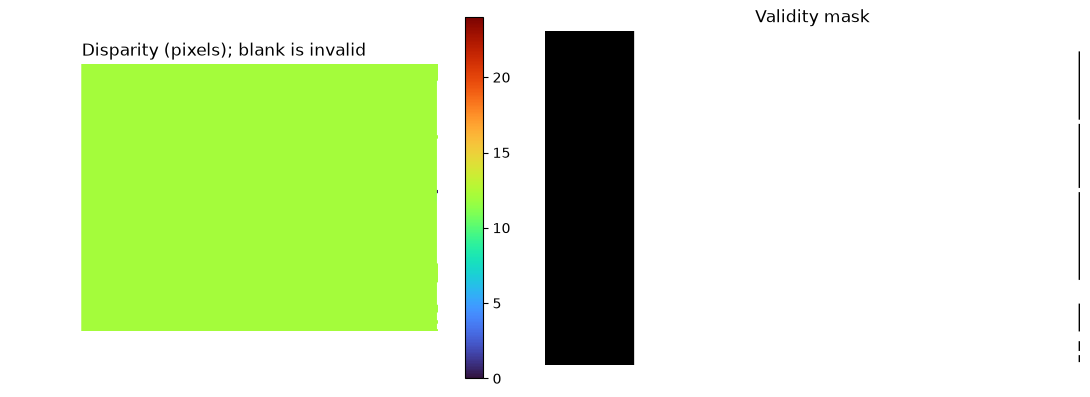

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
im = axes[0].imshow(np.ma.masked_where(~valid, disparity), cmap='turbo', vmin=0, vmax=24)
axes[0].set_title('Disparity (pixels); blank is invalid'); fig.colorbar(im, ax=axes[0])
axes[1].imshow(valid, cmap='gray'); axes[1].set_title('Validity mask')
for ax in axes: ax.axis('off')
plt.tight_layout(); plt.show()


## Step 3 — Convert to metric depth safely
Depth grows nonlinearly as disparity approaches zero. Fill invalid depths with `NaN`; do not divide by zero and then hide infinities. A far-depth cutoff is an application decision and should be recorded explicitly.


Median depth (m): 2.0
Depth absolute error median / 95th percentile (m): [0. 0.]


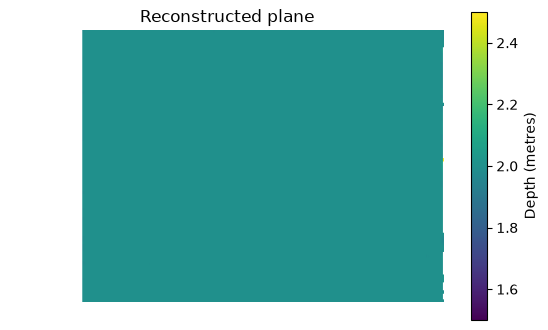

In [6]:
depth = np.full(disparity.shape, np.nan, np.float32)
np.divide(focal_px*baseline_m, disparity, out=depth, where=valid)
assert np.isfinite(depth[valid]).all() and np.isnan(depth[~valid]).all()
depth_error = np.abs(depth[evaluate]-depth_true_m)
print('Median depth (m):', np.median(depth[evaluate]))
print('Depth absolute error median / 95th percentile (m):', np.percentile(depth_error, [50, 95]))
assert np.median(depth_error) < 0.1
plt.figure(figsize=(7, 4))
plt.imshow(depth, cmap='viridis', vmin=1.5, vmax=2.5)
plt.colorbar(label='Depth (metres)'); plt.title('Reconstructed plane'); plt.axis('off'); plt.show()


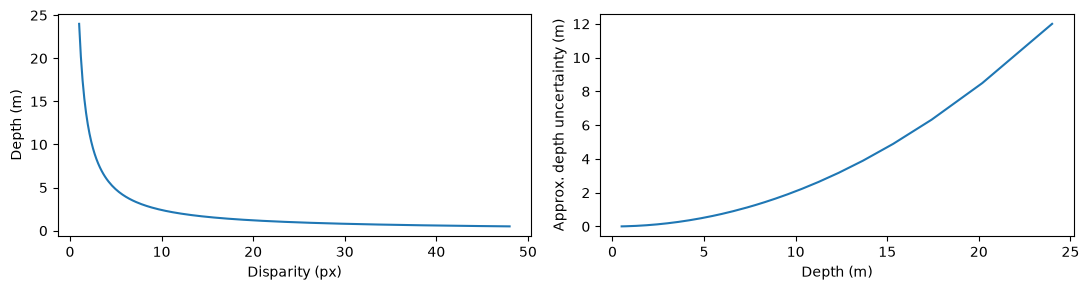

At d=12 px, 0.5 px error implies about 0.08333333333333333 m depth uncertainty.


In [7]:
sample_disparities = np.linspace(1, 48, 250)
sample_depths = focal_px*baseline_m/sample_disparities
sigma_disparity_px = 0.5
# First-order propagation: sigma_Z ≈ f*B/d² * sigma_d.
sigma_depth_m = focal_px*baseline_m/sample_disparities**2 * sigma_disparity_px
fig, axes = plt.subplots(1, 2, figsize=(11, 3))
axes[0].plot(sample_disparities, sample_depths); axes[0].set(xlabel='Disparity (px)', ylabel='Depth (m)')
axes[1].plot(sample_depths, sigma_depth_m); axes[1].set(xlabel='Depth (m)', ylabel='Approx. depth uncertainty (m)')
plt.tight_layout(); plt.show()
print('At d=12 px, 0.5 px error implies about', focal_px*baseline_m/12**2*0.5, 'm depth uncertainty.')


## Step 4 — Build a small 3D point cloud
For a rectified camera, `X=(u-cx)*Z/f`, `Y=(v-cy)*Z/f`. The result below uses metres, with y downward and z forward. Subsampling makes plotting fast; it does not change the reconstruction equations.


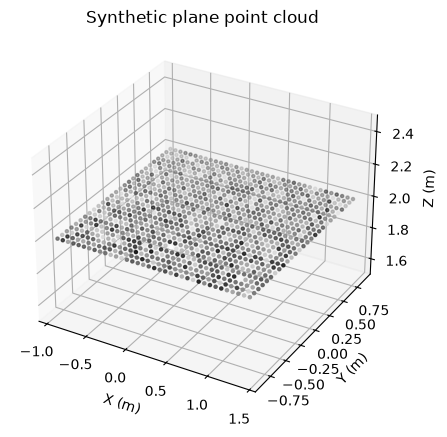

In [8]:
cx, cy = w/2, h/2
v, u = np.indices(depth.shape)
X = (u-cx)*depth/focal_px
Y = (v-cy)*depth/focal_px
cloud_mask = evaluate & ((u % 8) == 0) & ((v % 8) == 0)
cloud = np.column_stack([X[cloud_mask], Y[cloud_mask], depth[cloud_mask]])
assert len(cloud) > 100 and np.isfinite(cloud).all()
fig = plt.figure(figsize=(8, 5))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(cloud[:, 0], cloud[:, 1], cloud[:, 2], c=left[cloud_mask], cmap='gray', s=5)
ax.set(xlabel='X (m)', ylabel='Y (m)', zlabel='Z (m)', title='Synthetic plane point cloud')
ax.set_zlim(1.5, 2.5); plt.show()


In [9]:
stereo_dir = ROOT / 'outputs' / '15_stereo'
stereo_dir.mkdir(parents=True, exist_ok=True)
np.savez_compressed(stereo_dir / 'synthetic_depth.npz', disparity=disparity, depth_m=depth,
                    valid=valid, focal_px=focal_px, baseline_m=baseline_m)
np.savetxt(stereo_dir / 'plane_xyz_metres.csv', cloud, delimiter=',',
           header='X_m,Y_m,Z_m', comments='')
print('Saved arrays and point cloud to', stereo_dir)


Saved arrays and point cloud to C:\Users\Hareram ray\AI\OpencvPractical\outputs\15_stereo


## Step 5 — Test failure modes and parameters
Stereo matching assumes synchronized views, matching appearance, and rectification. Textureless areas and repeated patterns are ambiguous. Invalid-output masks are useful but cannot identify every confidently wrong match.


Rectified | valid coverage: 1.0 | median error: 0.0 | >1px errors: 0.0
Vertical offset 3px | valid coverage: 0.582 | median error: 14.938 | >1px errors: 0.95


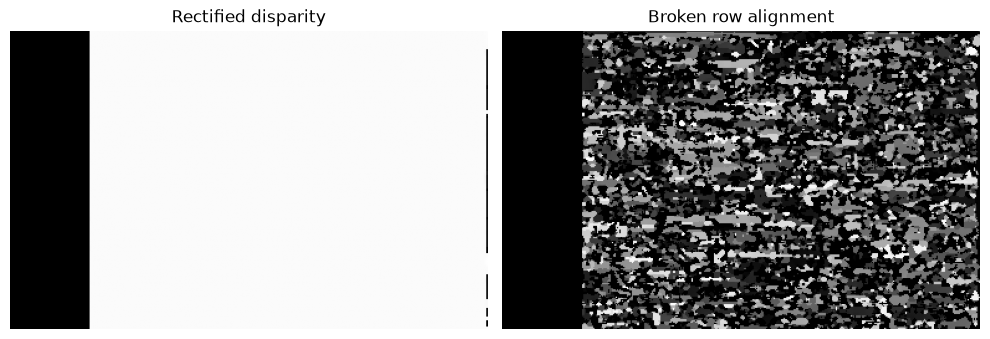

In [10]:
right_misaligned = cv2.warpAffine(right, np.float32([[1, 0, 0], [0, 1, 3]]), (w, h))
_, bad_disparity = compute_disparity(left, right_misaligned)
bad_valid = (bad_disparity > 0) & evaluation_region
for name, values, mask in [('Rectified', disparity, evaluate),
                            ('Vertical offset 3px', bad_disparity, bad_valid)]:
    errors = np.abs(values[mask]-disparity_true)
    print(name, '| valid coverage:', round(float(mask.sum()/evaluation_region.sum()), 3),
          '| median error:', round(float(np.median(errors)), 3) if errors.size else 'no matches',
          '| >1px errors:', round(float(np.mean(errors > 1)), 3) if errors.size else 'n/a')
show_images([disparity, bad_disparity], ['Rectified disparity', 'Broken row alignment'])


In [11]:
results = []
for window in [3, 5, 9, 15]:
    _, candidate = compute_disparity(left, right, block_size=window)
    mask = (candidate > 0) & evaluation_region
    results.append((window, mask.sum()/evaluation_region.sum(),
                    float(np.median(np.abs(candidate[mask]-disparity_true)))))
print('Block size | valid coverage | median disparity error')
for row_result in results:
    print(f'{row_result[0]:10} | {row_result[1]:14.3f} | {row_result[2]:.4f} px')


Block size | valid coverage | median disparity error
         3 |          1.000 | 0.0000 px
         5 |          1.000 | 0.0000 px
         9 |          1.000 | 0.0000 px
        15 |          1.000 | 0.0000 px


## Step 6 — Verify triangulation independently
`triangulatePoints` reconstructs homogeneous coordinates from corresponding pixels and two projection matrices. A homogeneous point `(Xh,Yh,Zh,Wh)` becomes Euclidean after division by `Wh`. This is a separate geometric check using perfect correspondences, not a claim that stereo matching always finds them.


In [12]:
K = np.array([[focal_px, 0, cx], [0, focal_px, cy], [0, 0, 1.]])
P_left = K @ np.column_stack([np.eye(3), np.zeros(3)])
P_right = K @ np.column_stack([np.eye(3), [-baseline_m, 0, 0]])
known_xyz = np.array([[-0.2, -0.1, 2.], [0.1, 0.05, 1.5], [0.3, 0.12, 3.]], dtype=np.float64)
homogeneous_xyz = np.column_stack([known_xyz, np.ones(len(known_xyz))]).T
pixels_left = P_left @ homogeneous_xyz; pixels_left = pixels_left[:2]/pixels_left[2]
pixels_right = P_right @ homogeneous_xyz; pixels_right = pixels_right[:2]/pixels_right[2]
reconstructed_h = cv2.triangulatePoints(P_left, P_right, pixels_left, pixels_right)
assert np.all(np.abs(reconstructed_h[3]) > 1e-10)
reconstructed = (reconstructed_h[:3]/reconstructed_h[3]).T
np.testing.assert_allclose(reconstructed, known_xyz, atol=1e-6)
print('Reconstructed XYZ (m):\n', reconstructed.round(4))


Reconstructed XYZ (m):
 [[-0.2  -0.1   2.  ]
 [ 0.1   0.05  1.5 ]
 [ 0.3   0.12  3.  ]]


### Practice
1. Double the baseline and keep the plane at 2 m. What disparity should the new synthetic pair have?
2. Forget the `/16` conversion deliberately in a separate variable. How wrong is the resulting depth?
3. Replace a central image patch with a uniform value in both images. Measure valid coverage and accuracy there. Explain why valid coverage alone is insufficient.

Do not change `disparity` in place; preserve a trustworthy reference result.


In [13]:
# Your experiment workspace.
new_baseline_m = 0.20
predicted_new_disparity_px = focal_px * new_baseline_m / depth_true_m
print('Prediction for the doubled baseline:', predicted_new_disparity_px, 'pixels')


Prediction for the doubled baseline: 24.0 pixels


### Worked solutions
The increased baseline improves geometric depth sensitivity in this ideal case, while real wide-baseline cameras also face larger occlusions and appearance differences.


Correct median depth: 2.0 m
Wrong unscaled-disparity depth: 0.125 m (16 times too small)
Textureless patch valid coverage: 1.0
Textureless patch median error: 0.0


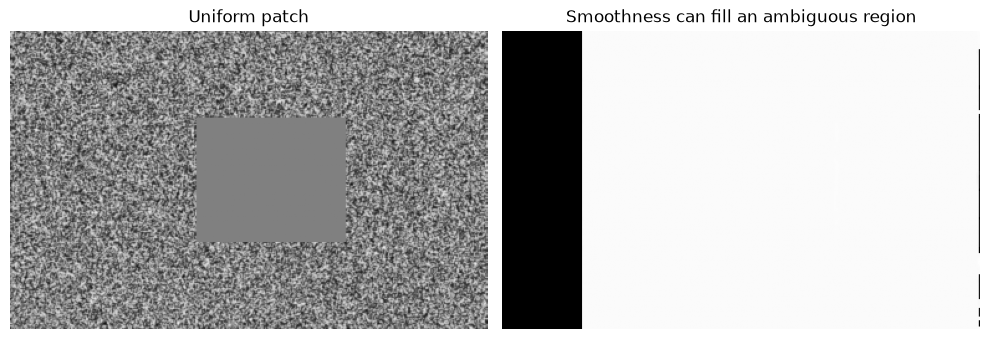

In [14]:
wrong_depth = focal_px*baseline_m/raw_disparity[evaluate].astype(float)
print('Correct median depth:', np.median(depth[evaluate]), 'm')
print('Wrong unscaled-disparity depth:', np.median(wrong_depth), 'm (16 times too small)')
flat_left, flat_right = left.copy(), right.copy()
flat_left[70:170, 150:270] = 128
flat_right[70:170, 150-disparity_true:270-disparity_true] = 128
_, flat_disp = compute_disparity(flat_left, flat_right)
patch = np.zeros_like(valid); patch[85:155, 170:250] = True
patch_valid = patch & (flat_disp > 0)
print('Textureless patch valid coverage:', patch_valid.sum()/patch.sum())
if patch_valid.any():
    print('Textureless patch median error:', np.median(np.abs(flat_disp[patch_valid]-disparity_true)))
show_images([flat_left, flat_disp], ['Uniform patch', 'Smoothness can fill an ambiguous region'])


### References and real-world extension
- [OpenCV StereoSGBM API](https://docs.opencv.org/4.x/d2/d85/classcv_1_1StereoSGBM.html)
- [OpenCV stereo depth tutorial](https://docs.opencv.org/4.x/dd/d53/tutorial_py_depthmap.html)
- [Calibration, stereoRectify, and triangulation API](https://docs.opencv.org/4.x/d9/d0c/group__calib3d.html)

A real stereo pipeline adds intrinsic calibration, `stereoCalibrate`, `stereoRectify`, and `initUndistortRectifyMap`/`remap` before matching. Validate known distances and left–right consistency, and record baseline units.
